# Wyniki: cały arkusz

Pilot: cały system na wszystkich budynkach jednego arkusza, na tanim modelu Haiku 5.5, żeby sprawdzić potok. Docelowo system ma działać na otwartym modelu, np. Qwen. W tym przebiegu: rekord BDOT10k, widoki i fasady, rubryka z literatury oraz pętla uzgadniania (`eksperymenty/arkusz_haiku.toml`). Budynki przy krawędzi bez pełnego widoku dostają szacunek z samego rekordu. Liczby dla każdego budynku: `wyniki/eksperymenty/arkusz_haiku.csv`.

Notatnik czyta zapisane wyniki i niczego nie wywołuje. Jednostką oceny liczby mieszkańców są kwadraty NSP 2021, w których szacunek ma każdy budynek mieszkalny. Dla pojedynczego budynku nie mamy referencji.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 88}}

import re
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from agenci import BAZA, PRZEBIEGI
from agenci.ewaluacja import ocena_kwadratow, podsumowanie, porownaj_sumy, sumy_kwadratow, wczytaj
from agenci.statystyka import budynki_w_kwadratach
from ortofoto.arkusze import czytaj, zasieg
from ortofoto.budynki import wczytaj_budynki

plt.rcParams.update({"figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#ececec", "axes.axisbelow": True})
KOLORY = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # kategorie, zawsze w tej kolejności
TUSZ, SZARY = "#333333", "#9a9a9a"
ROZJAZD = LinearSegmentedColormap.from_list("rozjazd", ["#1c5cab", "#86b6ef", "#f0efec", "#f2a27e", "#c2470f"])  # mało / dużo
NIEBIESKI = LinearSegmentedColormap.from_list("niebieski", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])


def tys(x):
    return f"{x:,.0f}".replace(",", " ")


def po_polsku(tekst):
    """Przecinek dziesiętny w tekście wyświetlanym czytelnikowi."""
    return re.sub(r"(\d)\.(\d)", r"\1,\2", tekst)


bud = wczytaj_budynki()
miasto, kw = budynki_w_kwadratach(zasieg())
wynik = wczytaj("arkusz_haiku").set_index("budynek")
dialog = pd.read_csv(PRZEBIEGI / "arkusz_haiku__dialog.csv").fillna({"zmiana": ""})
bilanse = pd.read_csv(PRZEBIEGI / "arkusz_haiku__bilans.csv").set_index("kod")
with sqlite3.connect(BAZA) as db:
    wydano = db.execute("SELECT SUM(koszt_usd) FROM wywolania").fetchone()[0]

display(Markdown(po_polsku(f"**Wszystkie przebiegi.** Łącznie zapłacono {wydano:.2f} USD. `usd` to koszt świadka, tak jakby przebieg szedł sam, bez pamięci odpowiedzi. "
                           "Próbki 40 budynków nie mają kompletnych kwadratów; porównanie modeli na nich jest w `proof_of_concept.ipynb`. Pętlę oceniamy na kwadratach sprzed uzgadniania.")))
podsumowanie().round(3)

**Wszystkie przebiegi.** Łącznie zapłacono 2,06 USD. `usd` to koszt świadka, tak jakby przebieg szedł sam, bez pamięci odpowiedzi. Próbki 40 budynków nie mają kompletnych kwadratów; porównanie modeli na nich jest w `proof_of_concept.ipynb`. Pętlę oceniamy na kwadratach sprzed uzgadniania.

,budynki,bledy,usd,suma_mieszkancow,kond_mae,kond_trafne,mieszk_trafnosc,mieszk_f1,n_kwadratow,kw_spearman,kw_spearman_lo,kw_spearman_hi,kw_wape,kw_wape_lo,kw_wape_hi
przebieg,,,,,,,,,,,,,,,
arkusz_haiku,341,0,0.281,8855.439,0.316,0.783,0.979,0.986,15,0.832,0.515,0.952,0.226,0.115,0.378
model_haiku_s2_bez_tabeli,40,0,0.031,1417.790,0.811,0.486,0.925,0.954,0,NaN,NaN,NaN,NaN,NaN,NaN
model_opus_s2_bez_tabeli,40,0,0.852,1497.522,1.000,0.432,0.950,0.969,0,NaN,NaN,NaN,NaN,NaN,NaN
model_sonnet_s2_bez_tabeli,40,0,0.387,1520.858,0.811,0.595,0.950,0.969,0,NaN,NaN,NaN,NaN,NaN,NaN
objetosc,341,0,0.000,2596995.130,NaN,NaN,0.724,0.840,15,0.311,-0.331,0.887,0.698,0.131,1.279
objetosc_bdot,341,0,0.000,1431834.230,NaN,NaN,1.000,1.000,15,0.846,0.518,0.977,0.209,0.110,0.316
petla_sonnet_proba,25,0,0.265,912.208,0.917,0.417,1.000,1.000,3,0.500,-1.000,1.000,0.541,0.000,0.949


## Liczba mieszkańców budynku

**Budynki: 341, błędy: 0.** Zamieszkane: 248, łącznie 8 855 os. (mediana 27, maksimum 341 os. na budynek). Bez zdjęć, z samego rekordu: 30 bud., 800 os.

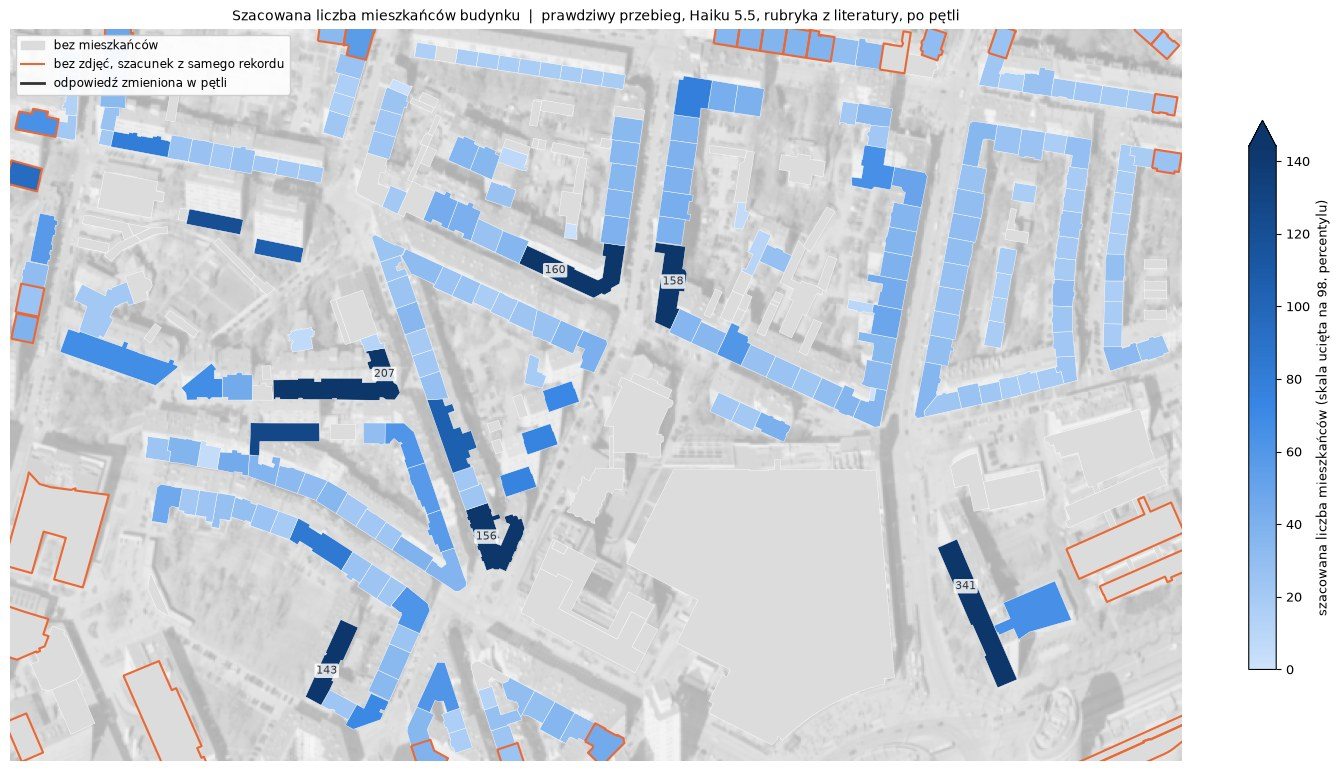

In [2]:
zamieszkane = wynik.mieszkancy[wynik.mieszkancy > 0]
bez_zdjec = wynik[wynik.liczba_widokow == 0]
display(Markdown(f"**Budynki: {len(wynik)}, błędy: {int(wynik.blad.notna().sum())}.** Zamieszkane: {len(zamieszkane)}, łącznie {tys(wynik.mieszkancy.sum())} os. "
                 f"(mediana {zamieszkane.median():.0f}, maksimum {zamieszkane.max():.0f} os. na budynek). Bez zdjęć, z samego rekordu: {len(bez_zdjec)} bud., {tys(bez_zdjec.mieszkancy.sum())} os."))

x0, y0, x1, y1 = zasieg().bounds
img, ext = czytaj("N", zasieg().bounds, 1.0)
tlo = 255 - (255 - img.mean(2)) * 0.35
mapa = bud.join(wynik[["mieszkancy", "liczba_widokow", "zmieniony"]])
fig, ax = plt.subplots(figsize=(15, 7.6), layout="constrained")
ax.imshow(tlo, extent=ext, cmap="gray", vmin=0, vmax=255)
mapa[mapa.mieszkancy.fillna(0) == 0].plot(ax=ax, color="#dcdcdc", edgecolor="white", linewidth=0.3)
mapa[mapa.mieszkancy > 0].plot(ax=ax, column="mieszkancy", cmap=NIEBIESKI, vmin=0, vmax=mapa.mieszkancy[mapa.mieszkancy > 0].quantile(0.98), edgecolor="white", linewidth=0.3,
                               legend=True, legend_kwds={"label": "szacowana liczba mieszkańców (skala ucięta na 98. percentylu)", "shrink": 0.75})
mapa[mapa.liczba_widokow == 0].boundary.plot(ax=ax, color=KOLORY[1], linewidth=1.5)
if wynik.zmieniony.any():
    mapa[mapa.zmieniony == True].boundary.plot(ax=ax, color=TUSZ, linewidth=2)  # noqa: E712
for _, b in mapa.nlargest(6, "mieszkancy").iterrows():
    p = b.geometry.representative_point()
    ax.text(p.x, p.y, f"{b.mieszkancy:.0f}", ha="center", va="center", fontsize=8, color=TUSZ, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax.legend(handles=[Patch(color="#dcdcdc", label="bez mieszkańców"), Line2D([], [], color=KOLORY[1], lw=1.5, label="bez zdjęć, szacunek z samego rekordu"),
                   Line2D([], [], color=TUSZ, lw=2, label="odpowiedź zmieniona w pętli")], loc="upper left", fontsize=8.5, framealpha=0.92)
ax.set(xlim=(x0, x1), ylim=(y0, y1), title="Szacowana liczba mieszkańców budynku  |  prawdziwy przebieg, Haiku 5.5, rubryka z literatury, po pętli")
ax.set_axis_off()
plt.show()

## Czy sumy zgadzają się ze spisem?

To jedyna ocena liczby mieszkańców, jaką dziś mamy. Stan przed pętlą jest oceną niezależną. Po pętli jest kolista, bo agent widział te sumy.

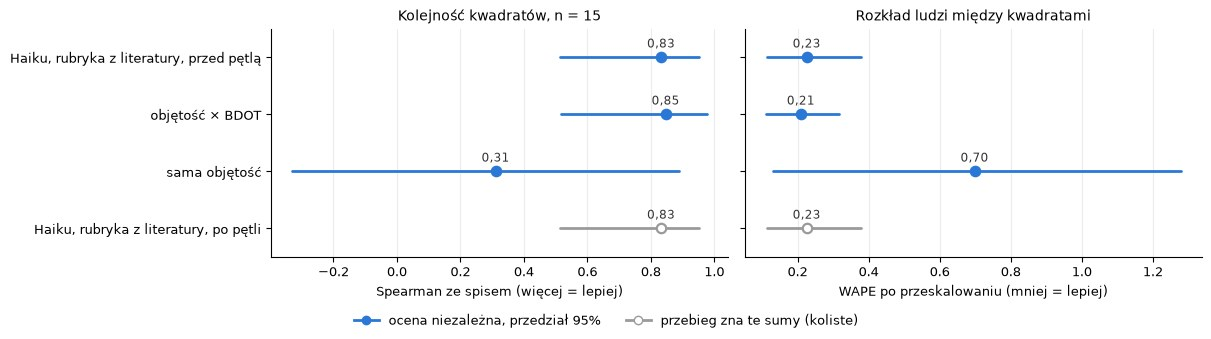

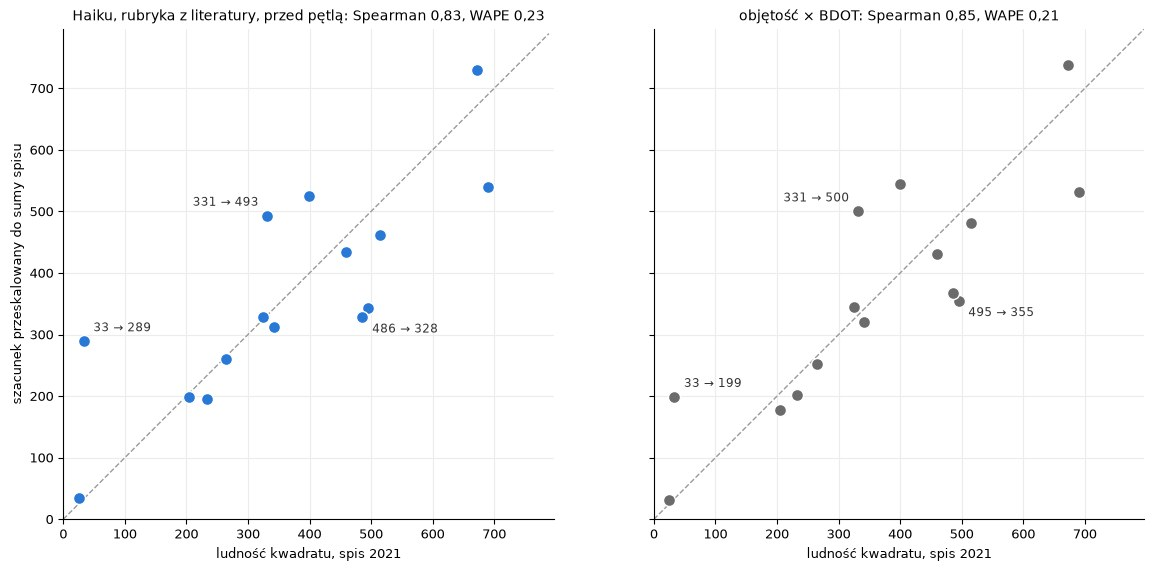

**Haiku a objętość × BDOT:** różnica Spearmana -0,01 [-0,15; +0,12], różnica WAPE +0,02 [-0,01; +0,08]. Oba przedziały obejmują zero, więc różnicy nie da się rozstrzygnąć.

**Jeden kwadrat ma tu dużą wagę.** W kwadracie z akademikiem spis podaje 33 os., baseline daje 199, a Haiku 289. Akademik ma setki miejsc, a spis liczy miejsce zamieszkania, nie pobyt, więc ten kwadrat mało mówi o trafności. Bez tego kwadratu różnica Spearmana to +0,00 [-0,12; +0,15], a WAPE +0,00 [-0,02; +0,03].

**Poziom jest niepewny:** na tych 15 kwadratach spis ma 5 476 os., a szacunek 6 445 os., czyli +18%. Wykresy powyżej usuwają tę różnicę skalą, a liczby w pliku CSV nie są skalowane. Na całym arkuszu to 8 855 os., a po przeskalowaniu do spisu z tych kwadratów ok. 7 524 os.

In [3]:
PRED = wynik.reset_index()
BDOT, OBJETOSC = wczytaj("objetosc_bdot"), wczytaj("objetosc")
t = pd.DataFrame([ocena_kwadratow(PRED, miasto, kw, "mieszkancy_r0") | {"podpis": "Haiku, rubryka z literatury, przed pętlą", "kolista": False},
                  ocena_kwadratow(BDOT, miasto, kw) | {"podpis": "objętość × BDOT", "kolista": False},
                  ocena_kwadratow(OBJETOSC, miasto, kw) | {"podpis": "sama objętość", "kolista": False},
                  ocena_kwadratow(PRED, miasto, kw) | {"podpis": "Haiku, rubryka z literatury, po pętli", "kolista": True}])
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3.3), sharey=True, layout="constrained")
for ax, miara, xlabel in ((a, "kw_spearman", "Spearman ze spisem (więcej = lepiej)"), (b, "kw_wape", "WAPE po przeskalowaniu (mniej = lepiej)")):
    for y, w in t.iterrows():
        kolor = SZARY if w.kolista else KOLORY[0]
        ax.plot([w[miara + "_lo"], w[miara + "_hi"]], [y, y], color=kolor, lw=2, solid_capstyle="round", zorder=2)
        ax.scatter(w[miara], y, s=46, facecolor="white" if w.kolista else kolor, edgecolor=kolor, linewidth=1.6, zorder=3)
        ax.annotate(f"{w[miara]:.2f}".replace(".", ","), (w[miara], y), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8.5, color=TUSZ)
    ax.set_yticks(range(len(t)), t.podpis)
    ax.set_ylim(len(t) - 0.5, -0.5)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
a.set_title(f"Kolejność kwadratów, n = {int(t.n_kwadratow.max())}")
b.set_title("Rozkład ludzi między kwadratami")
fig.legend(handles=[Line2D([], [], marker="o", color=KOLORY[0], lw=2, label="ocena niezależna, przedział 95%"),
                    Line2D([], [], marker="o", color=SZARY, markerfacecolor="white", lw=2, label="przebieg zna te sumy (koliste)")],
           loc="outside lower center", ncols=2, frameon=False)
plt.show()

fig, osie = plt.subplots(1, 2, figsize=(12, 5.6), sharex=True, sharey=True, layout="constrained")
for ax, (podpis, pred, kolumna, kolor) in zip(osie, [("Haiku, rubryka z literatury, przed pętlą", PRED, "mieszkancy_r0", KOLORY[0]), ("objętość × BDOT", BDOT, "mieszkancy", "#6b6b6b")]):
    suma, ref = sumy_kwadratow(pred, miasto, kw, kolumna)
    s = suma * ref.sum() / suma.sum()
    granica = 1.08 * max(s.max(), ref.max())
    ax.plot([0, granica], [0, granica], color=SZARY, ls="--", lw=1, zorder=1)
    ax.scatter(ref, s, s=75, color=kolor, edgecolor="white", linewidth=1, zorder=3)
    for kod_kwadratu in np.log((s + 1) / (ref + 1)).abs().nlargest(3).index:
        x, y = ref[kod_kwadratu], s[kod_kwadratu]
        w_lewo = y > x and x > 0.2 * granica  # etykieta przy osi szłaby poza wykres
        ax.annotate(f"{x:.0f} → {y:.0f}", (x, y), xytext=(-6, 7) if w_lewo else (7, 7 if y > x else -11), ha="right" if w_lewo else "left", textcoords="offset points", fontsize=8.5, color=TUSZ)
    w = t[t.podpis == podpis].iloc[0]
    ax.set(title=po_polsku(f"{podpis}: Spearman {w.kw_spearman:.2f}, WAPE {w.kw_wape:.2f}"), xlabel="ludność kwadratu, spis 2021", xlim=(0, granica), ylim=(0, granica), aspect="equal")
osie[0].set_ylabel("szacunek przeskalowany do sumy spisu")
plt.show()

a_, ref = sumy_kwadratow(PRED, miasto, kw, "mieszkancy_r0")
b_, _ = sumy_kwadratow(BDOT, miasto, kw)
d = porownaj_sumy(a_, b_, ref)
skalowany_a, skalowany_b = a_ * ref.sum() / a_.sum(), b_ * ref.sum() / b_.sum()
najgorszy = np.log((skalowany_b + 1) / (ref + 1)).abs().idxmax()  # kwadrat, w którym baseline myli się najbardziej
bez = porownaj_sumy(a_.drop(najgorszy), b_.drop(najgorszy), ref.drop(najgorszy))
display(Markdown(po_polsku(f"**Haiku a objętość × BDOT:** różnica Spearmana {d['d_spearman']:+.2f} [{d['d_spearman_lo']:+.2f}; {d['d_spearman_hi']:+.2f}], "
                           f"różnica WAPE {d['d_wape']:+.2f} [{d['d_wape_lo']:+.2f}; {d['d_wape_hi']:+.2f}]. Oba przedziały obejmują zero, więc różnicy nie da się rozstrzygnąć.\n\n"
                           f"**Jeden kwadrat ma tu dużą wagę.** W kwadracie z akademikiem spis podaje {ref[najgorszy]:.0f} os., baseline daje {skalowany_b[najgorszy]:.0f}, a Haiku {skalowany_a[najgorszy]:.0f}. "
                           f"Akademik ma setki miejsc, a spis liczy miejsce zamieszkania, nie pobyt, więc ten kwadrat mało mówi o trafności. Bez tego kwadratu różnica Spearmana to {bez['d_spearman']:+.2f} "
                           f"[{bez['d_spearman_lo']:+.2f}; {bez['d_spearman_hi']:+.2f}], a WAPE {bez['d_wape']:+.2f} [{bez['d_wape_lo']:+.2f}; {bez['d_wape_hi']:+.2f}].\n\n"
                           f"**Poziom jest niepewny:** na tych {d['n']} kwadratach spis ma {tys(ref.sum())} os., a szacunek {tys(a_.sum())} os., czyli {a_.sum() / ref.sum() - 1:+.0%}. "
                           f"Wykresy powyżej usuwają tę różnicę skalą, a liczby w pliku CSV nie są skalowane. Na całym arkuszu to {tys(wynik.mieszkancy.sum())} os., "
                           f"a po przeskalowaniu do spisu z tych kwadratów ok. {tys(wynik.mieszkancy.sum() * ref.sum() / a_.sum())} os.")))

Gdzie szacunek rozjeżdża się ze spisem na mapie. Niebieski znaczy za mało, pomarańczowy za dużo, a etykiety to ludność ze spisu. Gruba ramka wokół kwadratu to flaga rozjazdu.

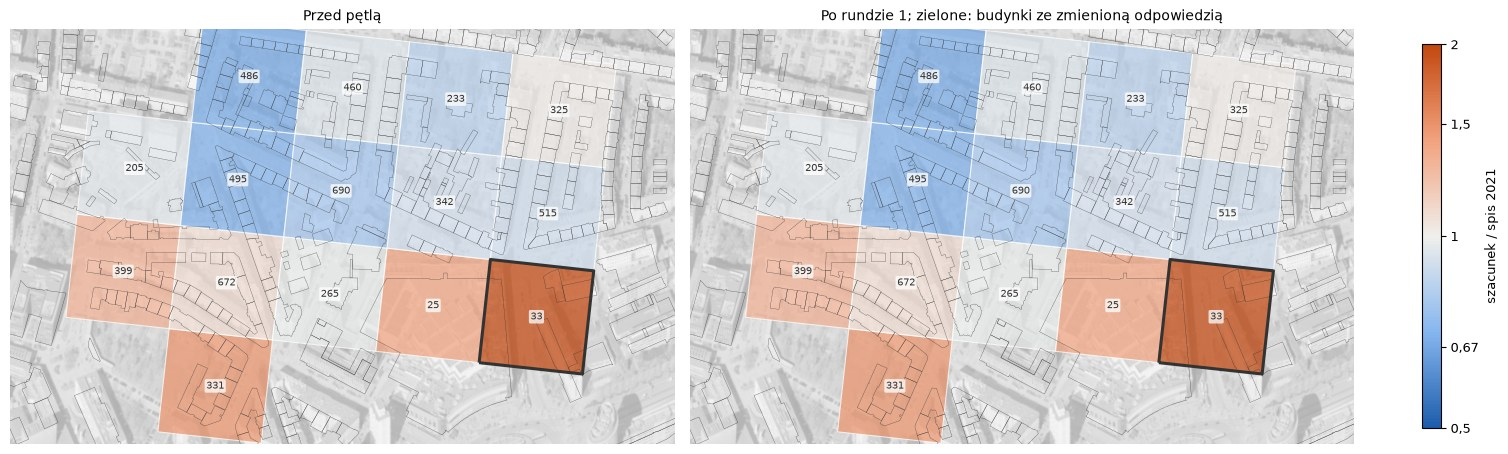

In [4]:
norma = LogNorm(0.5, 2)
zmienione = wynik.index[wynik.zmieniony]
fig, osie = plt.subplots(1, 2, figsize=(15, 5.2), layout="constrained")
for ax, runda in zip(osie, (0, int(bilanse.runda.max()))):
    r = bilanse[bilanse.runda == runda]
    ax.imshow(tlo, extent=ext, cmap="gray", vmin=0, vmax=255)
    kwadraty = kw.loc[r.index].assign(iloraz=r.iloraz)
    kwadraty.plot(ax=ax, column="iloraz", cmap=ROZJAZD, norm=norma, alpha=0.72, edgecolor="white", linewidth=0.8)
    if r.flaga.any():
        kwadraty[r.flaga].boundary.plot(ax=ax, color=TUSZ, linewidth=2.2)
    bud.boundary.plot(ax=ax, color=TUSZ, linewidth=0.2)
    if runda and len(zmienione):
        bud.loc[zmienione].boundary.plot(ax=ax, color=KOLORY[2], linewidth=2)
    for kod_kwadratu, w in r.iterrows():
        p = kw.geometry[kod_kwadratu].centroid
        if zasieg().contains(p):
            ax.text(p.x, p.y, f"{w.ludnosc:.0f}", ha="center", va="center", fontsize=7.5, color=TUSZ, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.75))
    ax.set(xlim=(x0, x1), ylim=(y0, y1), title="Przed pętlą" if runda == 0 else f"Po rundzie {runda}; zielone: budynki ze zmienioną odpowiedzią")
    ax.set_axis_off()
pasek = fig.colorbar(plt.cm.ScalarMappable(norm=norma, cmap=ROZJAZD), ax=osie, shrink=0.75, label="szacunek / spis 2021")
pasek.set_ticks([0.5, 0.67, 1, 1.5, 2], labels=["0,5", "0,67", "1", "1,5", "2"])
pasek.ax.minorticks_off()
plt.show()

## Kto gdzie mieszka

Typ budynku według świadka i rozkład szacunków. Kamienice dominują, bo tak wygląda ten fragment miasta; ten arkusz nie mówi nic o osiedlach domów jednorodzinnych.

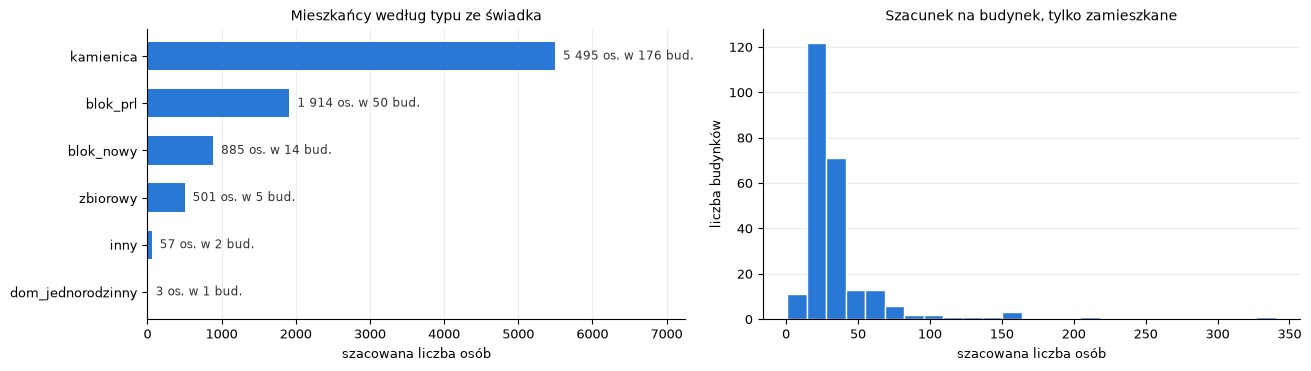

,funkcja,kond_bdot,pow_m2,typ,udzial_mieszkalny,pewnosc,mieszkancy
0,dom studencki,8.0,1467.0,zbiorowy,0.90,0.80,340.63
1,budynek wielorodzinny,6.0,1420.0,kamienica,0.90,0.60,206.84
2,budynek wielorodzinny,6.0,1161.0,blok_nowy,0.85,0.50,159.74
3,budynek wielorodzinny,8.0,863.0,blok_prl,0.85,0.60,158.21
4,budynek wielorodzinny,7.0,1032.0,kamienica,0.80,0.60,155.86
5,budynek wielorodzinny,8.0,738.0,blok_nowy,0.90,0.70,143.34
6,budynek wielorodzinny,8.0,659.0,blok_nowy,0.90,0.80,127.96
7,budynek wielorodzinny,12.0,392.0,blok_prl,0.95,0.85,120.64
8,budynek wielorodzinny,12.0,343.0,blok_prl,0.95,0.85,105.39
9,budynek wielorodzinny,6.0,765.0,kamienica,0.85,0.60,105.19


In [5]:
typy = wynik[wynik.mieszkancy > 0].groupby("typ").mieszkancy.agg(["sum", "size"]).sort_values("sum")
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 3.6), layout="constrained")
a.barh(typy.index, typy["sum"], color=KOLORY[0], height=0.6)
for y, (suma_typu, liczba) in enumerate(zip(typy["sum"], typy["size"])):
    a.text(suma_typu, y, f"  {tys(suma_typu)} os. w {liczba} bud.", va="center", fontsize=8.5, color=TUSZ)
a.set(title="Mieszkańcy według typu ze świadka", xlabel="szacowana liczba osób", xlim=(0, typy["sum"].max() * 1.32))
a.grid(axis="y", visible=False)
b.hist(wynik.mieszkancy[wynik.mieszkancy > 0], bins=25, color=KOLORY[0], edgecolor="white")
b.set(title="Szacunek na budynek, tylko zamieszkane", xlabel="szacowana liczba osób", ylabel="liczba budynków")
b.grid(axis="x", visible=False)
plt.show()

t = wynik.nlargest(10, "mieszkancy").join(bud[["funkcja"]]).join(bud.kondygnacje.rename("kond_bdot"))
t["pow_m2"] = bud.geometry.area.reindex(t.index).round()
t[["funkcja", "kond_bdot", "pow_m2", "typ", "udzial_mieszkalny", "pewnosc", "mieszkancy"]].round(2).reset_index(drop=True)

## Co zrobiła pętla

Wszystkie pytania agenta bilansującego i odpowiedzi świadka w tym przebiegu. Świadek widzi tu rekord BDOT10k, więc poprawki zgodne z rekordem nie są niezależnym potwierdzeniem.

In [6]:
kroki = ["**Flagi rozjazdu po rundach:** " + ", ".join(f"runda {int(n)}: {int(f)}" for n, f in bilanse.groupby("runda").flaga.sum().items()) +
         f". **Suma na arkuszu:** {tys(wynik.mieszkancy_r0.sum())} przed pętlą, {tys(wynik.mieszkancy.sum())} po niej."]
for w in dialog.itertuples():
    if w.rodzaj == "kwadrat":
        k = bilanse[bilanse.runda == w.runda - 1].loc[w.kod]
        kroki.append(f"**Agent, runda {w.runda:.0f}: kwadrat ze spisem {k.ludnosc:.0f} os. i szacunkiem {k.szacunek:.0f} os.** Diagnoza `{w.diagnoza}`.\n\n> {w.uzasadnienie}")
    elif w.rodzaj == "pytanie":
        b = bud.loc[w.budynek]
        kroki.append(f"**{b.funkcja}, {b.geometry.area:.0f} m².** Pytanie: *{w.pytanie}*\n\n> {w.odpowiedz}\n\n"
                     f"Zmiana: {w.zmiana or 'brak'}. Szacunek budynku: {w.mieszkancy_przed:.0f} -> {w.mieszkancy_po:.0f} os.")
display(Markdown("\n\n".join(kroki)))

**Flagi rozjazdu po rundach:** runda 0: 1, runda 1: 1. **Suma na arkuszu:** 8 855 przed pętlą, 8 855 po niej.

**Agent, runda 1: kwadrat ze spisem 33 os. i szacunkiem 289 os.** Diagnoza `rubryka`.

> Prawie cały szacunek (około 290 z 289 os.) daje jeden dom studencki o 8 kondygnacjach i udziale mieszkalnym 0,90, przeliczony wartością klasy zbiorowej 31 m² na osobę, a opisy budynków w tym kwadracie są zgodne z BDOT10k, więc rozjazd wynika głównie z przyjętej wartości dla klasy zbiorowej.

**dom studencki, 1467 m².** Pytanie: *Proszę jeszcze raz obejrzeć parter tego budynku i określić, jaką część jego powierzchni zajmują lokale usługowe lub handlowe (np. widoczne szyldy, witryny, wejścia), a jaką część stanowią wejścia i pomieszczenia związane z mieszkaniem studentów.*

> Ponownie oglądając parter, nie widzę na zdjęciach wyraźnych witryn ani szyldów sklepowych. Na fasadzie E parter ma jednorodny rytm okien pokojowych i wejść, więc utrzymuję udział mieszkalny 0,9, choć BDOT wskazuje aptekę i obiekt handlowo-usługowy, które mogą zajmować niewielką część parteru w narożu.

Zmiana: brak. Szacunek budynku: 341 -> 341 os.

**budynek wielorodzinny, 274 m².** Pytanie: *Proszę ponownie obejrzeć ten obiekt i opisać, czy widać na nim prowadzone prace budowlane (np. rusztowania, maszyny, ogrodzenie z tablicami), czy budynek wygląda na ukończony i użytkowany, oraz czy jego obrys na zdjęciach odpowiada obrysowi z bazy BDOT10k.*

> Widok W pokazuje obrys podstawy na terenie ogrodzonym banerowym płotem z tablicą kampanii, z wykopanym lub odsłoniętym podłożem i rusztowaniopodobnymi konstrukcjami, co wskazuje na prace na placu. Widok S pokazuje jednak wielokondygnacyjną elewację z regularnymi oknami, więc obraz jest niejednoznaczny i pewność obniżam do 0,5.

Zmiana: brak. Szacunek budynku: 0 -> 0 os.

**Agent, runda 2: kwadrat ze spisem 33 os. i szacunkiem 289 os.** Diagnoza `rubryka`.

> Prawie cały szacunek (około 290 z 289 osób) pochodzi z domu studenckiego, którego opis jest spójny z BDOT10k, więc rozjazd 8,54 wynika głównie z przyjętej wartości 31 m² na osobę dla klasy zbiorowej, a nie z błędnego opisu budynku.

## Jak to czytać

- **Dla pojedynczego budynku nie ma sprawdzenia.** Ocena dotyczy sum w kwadratach, więc liczba na konkretnym budynku to szacunek ze wzoru.
- **Nie widać przewagi nad baseline'em.** Przy 15 kwadratach przedziały różnicy obejmują zero, a obie miary są prawie takie same. Ten przebieg nie pokazuje też, czy pomagają obrazy, bo porównuje cały system z objętością: do tego potrzebne są warianty bez obrazów i z obrazami innego budynku.
- **Zgodność z BDOT10k jest tu kolista.** Świadek widzi rekord, a jego odpowiedzi czasem wprost się na niego powołują.
- **Zamieszkanie zbiorowe to najsłabsza liczba rubryki.** 31 m² na miejsce to mediana z amerykańskich akademików, a klasa obejmuje też klasztory i domy opieki. Spis liczy miejsce zamieszkania, a nie pobyt, więc w kwadracie z akademikiem wyjdzie rozjazd nawet przy dobrym szacunku.
- **Pętla mało zmienia.** Ma niewiele flag, a odpowiedź świadka zależy też od sformułowania pytania.